# Latent Diffusion on FashionMNIST: VAE latents, cross-attention U-Net, classifier-free guidance

This notebook builds a small **Latent Diffusion Model (LDM)**. The diffusion model never touches pixels. It learns to denoise the compressed latent space of a pretrained Stable Diffusion VAE, and it is conditioned on the FashionMNIST class through label embeddings, cross-attention, and classifier-free guidance (CFG).

| Part | Content |
|---|---|
| 1 | Pretrained VAE (`stabilityai/sd-vae-ft-mse`): encode FashionMNIST, scale latents by $s = 0.18215$, decode, and measure reconstruction MSE |
| 2 | Forward diffusion in latent space, $q(z_t \mid z_0) = \mathcal N(\sqrt{\bar\alpha_t}\,z_0, (1-\bar\alpha_t)I)$, with $T = 1000$ and linear $\beta_t \in [10^{-4}, 0.02]$. Noisy latents are decoded at $t \in \{0, 200, 500, 800, 1000\}$ |
| 3 | Conditional U-Net denoiser: base 64, multipliers (1, 2, 4), sinusoidal time embedding + MLP, ResBlocks with GroupNorm + SiLU, self-attention at 16×16 and in the bottleneck, label embeddings (10 classes + null) |
| 4 | Training: noise prediction, 50 epochs, lr $2\times10^{-5}$, labels dropped to the null label with probability 0.1 |
| 5 | Sampling with CFG, $\epsilon = (1+w)\,\epsilon_\text{cond} - w\,\epsilon_\text{uncond}$, $w = 3$: a 64-image grid with labels 0–9 repeated, plus an evaluation of the guidance scale |

**Timestep convention** (the same as HW8): every schedule tensor has length $T+1$, and index 0 is the clean latent ($\beta_0 = 0$, $\bar\alpha_0 = 1$). Training draws $t \sim \mathcal U\{1,\dots,T\}$.

**How the spec was read where it is ambiguous**

* *"Input: 1-channel image (FashionMNIST)".* The 1-channel image is the input to the **pipeline**. The U-Net itself operates on latents, as the same section requires, so its input and output have the VAE's **4 latent channels**. The SD VAE expects RGB at a multiple of 8 pixels. Each 28×28 image is therefore upsampled to 128×128, copied to 3 channels, and encoded to a **4×16×16** latent. At that size, "self-attention at 16×16" is the U-Net's first (full-resolution) level, and the bottleneck runs at 4×4.
* *Cross-attention conditioning* is named in the task overview, and *label + time embeddings* in Part 3. The model uses both. The label embedding is added to the time embedding and fed to every ResBlock. Each attention block also cross-attends from the latent tokens to a short sequence of label tokens (the LDM / Stable Diffusion conditioning mechanism, with a class label in place of text).

In [1]:
import os, sys, math, time, copy
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import diffusers
from diffusers import AutoencoderKL
from torchvision import datasets
from torchvision.utils import make_grid

SEED = 1605                                   # SID4; every random choice below is derived from it
torch.manual_seed(SEED); np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available() else "cpu")
print("device:", device, "| python", sys.version.split()[0], "| torch", torch.__version__, "| diffusers", diffusers.__version__)

SMOKE = os.environ.get("LDM_SMOKE") == "1"   # quick end-to-end check on a data subset; the reported run has SMOKE = False
OUT = Path("smoke") if SMOKE else Path(".")
FIG_DIR = OUT / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
CKPT = OUT / "ldm_fashionmnist.pt"
LATENT_CACHE = OUT / "latents_train.pt"

# ---- configuration (from the assignment) ----
VAE_ID = "stabilityai/sd-vae-ft-mse"
SCALE = 0.18215                               # standard SD latent scaling factor s
T = 1000
BETA_START, BETA_END = 1e-4, 0.02
BASE_CH, CH_MULT = 64, (1, 2, 4)
N_CLASSES = 10
NULL_LABEL = N_CLASSES                        # label 10 = "no label" for classifier-free guidance
P_UNCOND = 0.1
EPOCHS = 1 if SMOKE else 50
LR = 2e-5
GUIDANCE = 3.0

# ---- choices not fixed by the assignment ----
IMG_SIZE = 128                                # 128x128 pixels -> 4x16x16 latents (VAE downsamples by 8)
N_RES = 2                                     # ResBlocks per U-Net level
BATCH_SIZE = 128
N_TRAIN = 2048 if SMOKE else 60000            # training images encoded to latents
N_RECON = 128 if SMOKE else 2000              # test images used for the reconstruction check
N_EVAL = 20 if SMOKE else 500                 # samples per setting in the guidance evaluation

CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

def sync():
    if device.type == "cuda": torch.cuda.synchronize()
    elif device.type == "mps": torch.mps.synchronize()

device: mps | python 3.13.7 | torch 2.11.0 | diffusers 0.42.1


## 1. VAE compression and latent representation

The Stable Diffusion VAE (`sd-vae-ft-mse`, the KL-f8 autoencoder with its decoder fine-tuned on an MSE-weighted loss) maps an RGB image $x \in [-1,1]^{3\times H\times W}$ to a diagonal Gaussian posterior over a latent of shape $4 \times H/8 \times W/8$. We use the **posterior mean** as $z_0$, so the cached latents are deterministic, and then multiply by $s = 0.18215$. This is the constant Stable Diffusion uses to bring its latents to roughly unit variance, which is what the diffusion prior $\mathcal N(0, I)$ assumes.

The VAE is frozen; only the U-Net in Part 3 is trained.

In [2]:
train_set = datasets.FashionMNIST("./data", train=True, download=True)
test_set  = datasets.FashionMNIST("./data", train=False, download=True)

X_train = train_set.data.float().div(255.).unsqueeze(1)          # (60000,1,28,28) in [0,1]
y_train = train_set.targets.clone()
X_test  = test_set.data.float().div(255.).unsqueeze(1)
y_test  = test_set.targets.clone()
print(X_train.shape, X_test.shape)

vae = AutoencoderKL.from_pretrained(VAE_ID).to(device).eval().requires_grad_(False)
print(f"VAE parameters: {sum(p.numel() for p in vae.parameters()) / 1e6:.1f}M")

def to_vae_input(x):
    # (B,1,28,28) in [0,1] -> (B,3,128,128) in [-1,1]: the SD VAE expects RGB at a multiple of 8 pixels
    x = F.interpolate(x, size=IMG_SIZE, mode="bilinear", align_corners=False)
    return (x * 2 - 1).repeat(1, 3, 1, 1)

def from_vae_output(x):
    # (B,3,128,128) in [-1,1] -> (B,1,128,128) grayscale in [0,1]
    return ((x.clamp(-1, 1) + 1) / 2).mean(1, keepdim=True)

@torch.no_grad()
def encode(x, bs=64, log_every=None):
    # z0 = s * mean of the VAE posterior q(z | x)
    out, t0 = [], time.time()
    for k, i in enumerate(range(0, len(x), bs)):
        out.append(vae.encode(to_vae_input(x[i:i + bs].to(device))).latent_dist.mean * SCALE)
        if log_every and (k + 1) % log_every == 0:
            print(f"  encoded {i + bs:6d}/{len(x)}  ({time.time() - t0:.0f}s)")
    return torch.cat(out)

@torch.no_grad()
def decode(z, bs=32):
    # Undo the scaling and decode: (B,4,16,16) -> (B,1,128,128) in [0,1]
    return torch.cat([from_vae_output(vae.decode(z[i:i + bs].to(device) / SCALE).sample)
                      for i in range(0, len(z), bs)])

def to28(x):
    # Area-downsample decoded 128x128 images back to FashionMNIST resolution (on CPU: MPS needs divisible sizes)
    return F.interpolate(x.cpu(), size=28, mode="area")

torch.Size([60000, 1, 28, 28]) torch.Size([10000, 1, 28, 28])


/Users/rajesh_paruchuri/Desktop/GENAI/Homeworks/HW_9/.venv/lib/python3.13/site-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


VAE parameters: 83.7M


### Reconstruction check

We encode test images, decode the scaled latents (dividing by $s$ first), and compare with the inputs. The MSE is reported on a $[0,1]$ pixel scale in two ways:

* at **128×128** against the exact image the VAE received (the upsampled input), which measures the VAE alone;
* at **28×28** against the original FashionMNIST image, after area-downsampling the reconstruction. This includes the resize round trip. That part is measured separately by skipping the VAE.

In [3]:
x_in = X_test[:N_RECON]
sync(); t0 = time.time()
z_test = encode(x_in)
x_rec = decode(z_test)
sync(); dt = time.time() - t0

ref128 = (to_vae_input(x_in.to(device))[:, :1] + 1) / 2                  # what the VAE actually saw, in [0,1]
mse128 = F.mse_loss(x_rec, ref128).item()
mse28 = F.mse_loss(to28(x_rec).cpu(), x_in).item()
mse28_resize_only = F.mse_loss(to28(ref128).cpu(), x_in).item()
psnr = lambda m: 10 * math.log10(1 / m)

print(f"{N_RECON} test images, encode + decode {dt:.1f}s ({1000 * dt / N_RECON:.0f} ms/image)")
print(f"latent shape {tuple(z_test.shape[1:])}  (compression {28 * 28} px -> {z_test[0].numel()} latent values at 28x28; "
      f"{3 * IMG_SIZE ** 2} -> {z_test[0].numel()} = {3 * IMG_SIZE ** 2 / z_test[0].numel():.0f}x at the VAE input)")
print(f"reconstruction MSE @128x128 vs VAE input : {mse128:.6f}  (PSNR {psnr(mse128):.2f} dB)")
print(f"reconstruction MSE @28x28  vs original   : {mse28:.6f}  (PSNR {psnr(mse28):.2f} dB)")
print(f"  of which resize round trip alone       : {mse28_resize_only:.6f}")
per_class = [F.mse_loss(to28(x_rec[y_test[:N_RECON] == c]).cpu(), x_in[y_test[:N_RECON] == c]).item() for c in range(N_CLASSES)]
print("per-class MSE @28x28:", "  ".join(f"{CLASSES[c]} {m:.4f}" for c, m in enumerate(per_class)))

2000 test images, encode + decode 1546.2s (773 ms/image)
latent shape (4, 16, 16)  (compression 784 px -> 1024 latent values at 28x28; 49152 -> 1024 = 48x at the VAE input)
reconstruction MSE @128x128 vs VAE input : 0.000196  (PSNR 37.09 dB)
reconstruction MSE @28x28  vs original   : 0.003461  (PSNR 24.61 dB)
  of which resize round trip alone       : 0.003171
per-class MSE @28x28: T-shirt/top 0.0030  Trouser 0.0034  Pullover 0.0041  Dress 0.0034  Coat 0.0035  Sandal 0.0037  Shirt 0.0035  Sneaker 0.0028  Bag 0.0038  Ankle boot 0.0032


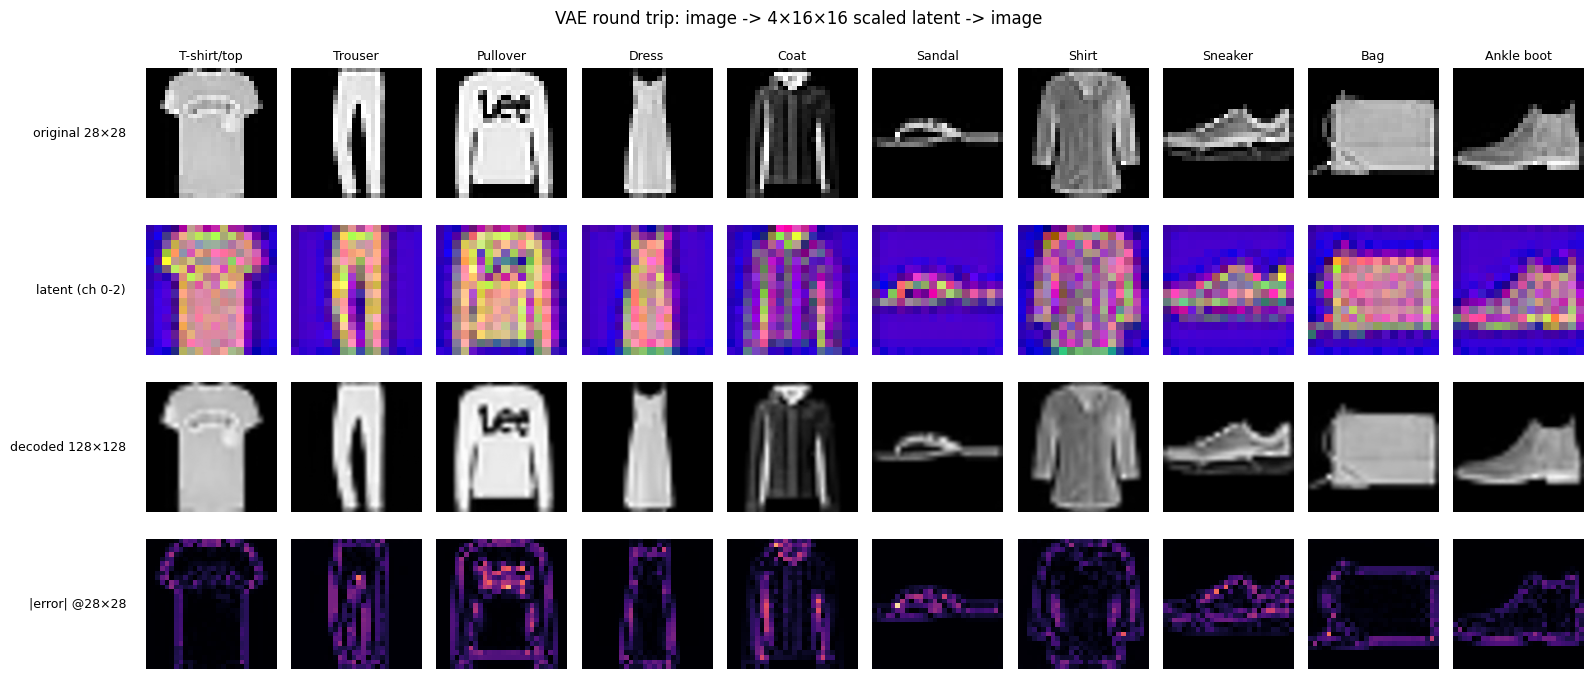

In [4]:
idx = [int((y_test[:N_RECON] == c).nonzero()[0]) for c in range(N_CLASSES)]   # first test image of each class
fig, axes = plt.subplots(4, N_CLASSES, figsize=(1.6 * N_CLASSES, 7))
for j, i in enumerate(idx):
    axes[0, j].imshow(x_in[i, 0], cmap="gray", vmin=0, vmax=1); axes[0, j].set_title(CLASSES[j], fontsize=9)
    axes[1, j].imshow(z_test[i].permute(1, 2, 0)[..., :3].cpu().add(2).div(4).clamp(0, 1))   # first 3 latent channels as RGB
    axes[2, j].imshow(x_rec[i, 0].cpu(), cmap="gray", vmin=0, vmax=1)
    axes[3, j].imshow((to28(x_rec[i:i + 1])[0, 0].cpu() - x_in[i, 0]).abs(), cmap="magma", vmin=0, vmax=0.5)
for ax in axes.flat: ax.axis("off")
for r, name in enumerate(["original 28×28", "latent (ch 0-2)", "decoded 128×128", "|error| @28×28"]):
    axes[r, 0].text(-0.15, 0.5, name, transform=axes[r, 0].transAxes, ha="right", va="center", fontsize=9)
fig.suptitle("VAE round trip: image -> 4×16×16 scaled latent -> image")
plt.tight_layout(); plt.savefig(FIG_DIR / "1_vae_reconstruction.png", dpi=150, bbox_inches="tight"); plt.show()

### Encoding the training set

All 60,000 training images are encoded once. The scaled latents (60000 × 4 × 16 × 16, about 245 MB) are cached to disk and kept on the device for training, so the expensive VAE encoder is never run inside the training loop.

In [5]:
if LATENT_CACHE.exists():
    Z_train = torch.load(LATENT_CACHE)["z"]
    print(f"loaded cached latents from {LATENT_CACHE}")
else:
    sync(); t0 = time.time()
    Z_train = encode(X_train[:N_TRAIN], log_every=100).cpu()
    sync(); print(f"encoded {N_TRAIN} training images in {time.time() - t0:.0f}s")
    torch.save({"z": Z_train, "y": y_train[:N_TRAIN]}, LATENT_CACHE)

Z_train, y_train_d = Z_train.to(device), y_train[:N_TRAIN].to(device)
print("Z_train", tuple(Z_train.shape), f"mean {Z_train.mean().item():.4f}  std {Z_train.std().item():.4f}")
print("per-channel mean", [round(v, 3) for v in Z_train.mean((0, 2, 3)).tolist()],
      " std", [round(v, 3) for v in Z_train.std((0, 2, 3)).tolist()])
print(f"unscaled latent std {Z_train.std().item() / SCALE:.3f}  ->  scaled by s = {SCALE}")

  encoded   6400/60000  (508s)


  encoded  12800/60000  (1022s)


  encoded  19200/60000  (1538s)


  encoded  25600/60000  (2182s)


  encoded  32000/60000  (2724s)


...

  encoded  51200/60000  (4589s)


  encoded  57600/60000  (5151s)


encoded 60000 training images in 5421s


Z_train (60000, 4, 16, 16) mean -0.0391  std 1.2652


per-channel mean [-0.122, -1.271, 0.657, 0.58]  std [1.149, 1.356, 0.585, 0.714]
unscaled latent std 6.946  ->  scaled by s = 0.18215


## 2. Forward diffusion in latent space

With $\alpha_t = 1 - \beta_t$ and $\bar\alpha_t = \prod_{s=1}^{t}\alpha_s$, a noisy latent at any timestep can be drawn in closed form:

$$z_t = \sqrt{\bar\alpha_t}\,z_0 + \sqrt{1-\bar\alpha_t}\,\epsilon,\qquad \epsilon\sim\mathcal N(0, I).$$

The only difference from pixel-space DDPM is that $z_0$ is a scaled VAE latent instead of an image. To see what the noise does, we decode $z_t$ back to pixels with the VAE decoder.

In [6]:
class Schedule:
    # Linear beta schedule; index 0 = clean latent (beta_0 = 0, alpha_bar_0 = 1). All tensors have length T+1.
    def __init__(self, beta_start, beta_end, T=T):
        self.betas = torch.cat([torch.zeros(1), torch.linspace(beta_start, beta_end, T)]).to(device)
        self.alphas = 1.0 - self.betas
        self.alpha_bars = torch.cumprod(self.alphas, dim=0)

spec = Schedule(BETA_START, BETA_END)
betas, alphas, alpha_bars = spec.betas, spec.alphas, spec.alpha_bars

def q_sample(z0, t, noise=None):
    # Noise injection: z_t = sqrt(abar_t) z0 + sqrt(1 - abar_t) eps. t: (B,) long in [0, T]
    if noise is None:
        noise = torch.randn_like(z0)
    ab = alpha_bars[t].view(-1, 1, 1, 1)
    return ab.sqrt() * z0 + (1 - ab).sqrt() * noise, noise

for t in [0, 200, 500, 800, 1000]:
    print(f"t = {t:4d}  alpha_bar = {alpha_bars[t].item():.5f}  signal {alpha_bars[t].sqrt().item():.4f}  noise {(1 - alpha_bars[t]).sqrt().item():.4f}")

t =    0  alpha_bar = 1.00000  signal 1.0000  noise 0.0000
t =  200  alpha_bar = 0.65904  signal 0.8118  noise 0.5839
t =  500  alpha_bar = 0.07859  signal 0.2803  noise 0.9599
t =  800  alpha_bar = 0.00153  signal 0.0391  noise 0.9992
t = 1000  alpha_bar = 0.00004  signal 0.0064  noise 1.0000


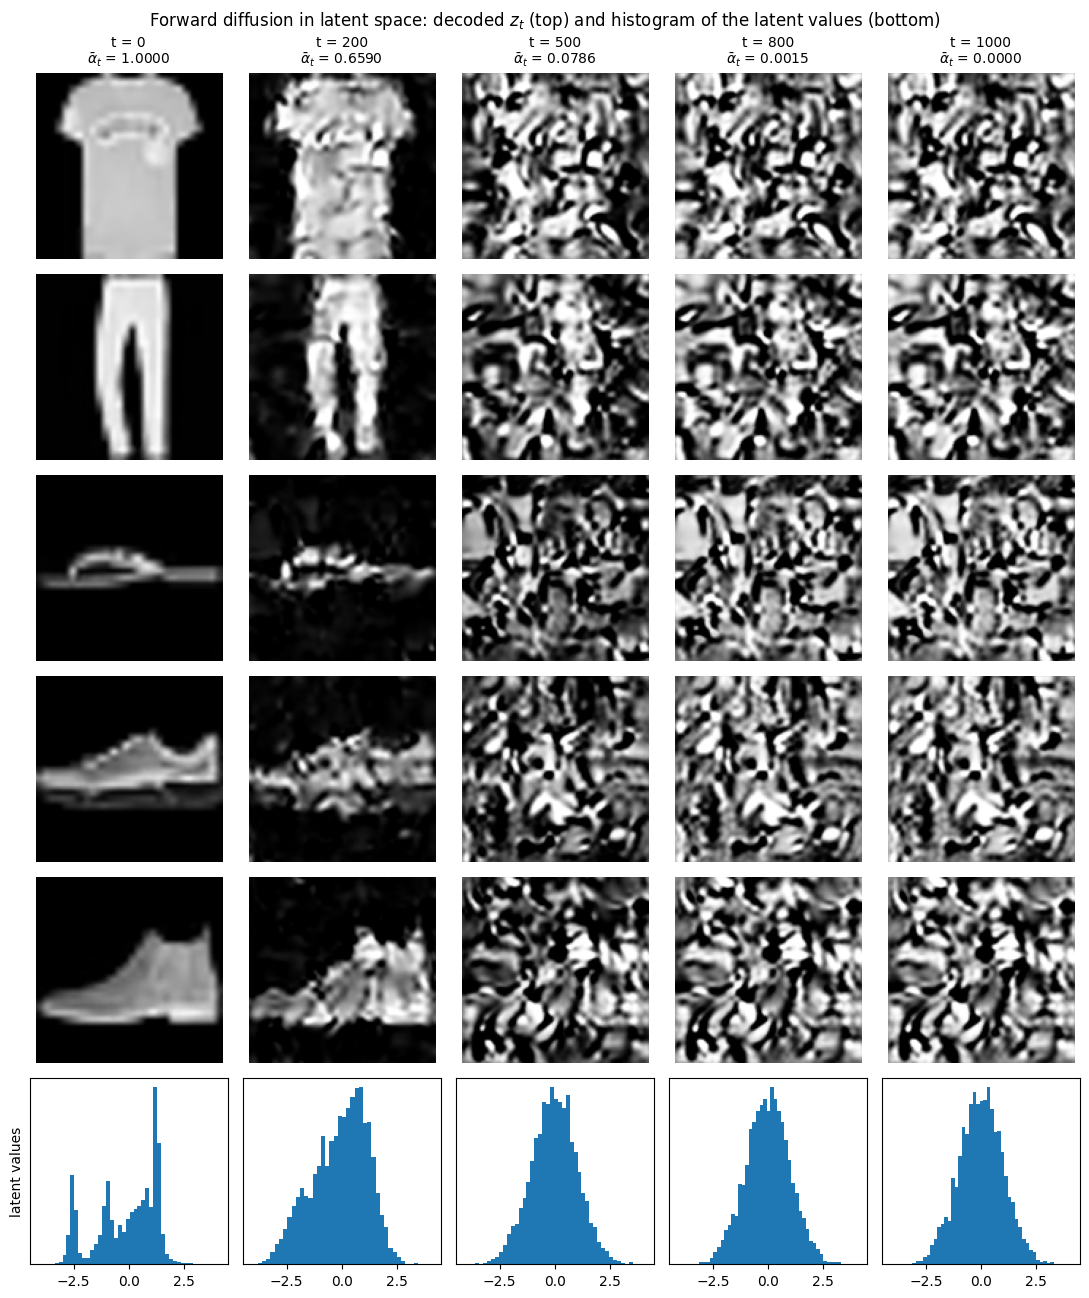

In [7]:
show_ts = [0, 200, 500, 800, 1000]
rows = [0, 1, 5, 7, 9]                                           # T-shirt, Trouser, Sandal, Sneaker, Ankle boot
z0 = z_test[[idx[c] for c in rows]]
g = torch.Generator(device="cpu").manual_seed(SEED + 1)
eps = torch.randn(z0.shape, generator=g).to(device)              # same eps for every t, so only the scaling changes

zts = torch.cat([q_sample(z0, torch.full((len(z0),), t, device=device), eps)[0] for t in show_ts])
imgs = decode(zts).view(len(show_ts), len(rows), 1, IMG_SIZE, IMG_SIZE)

fig, axes = plt.subplots(len(rows) + 1, len(show_ts), figsize=(2.2 * len(show_ts), 2.2 * (len(rows) + 1)))
for j, t in enumerate(show_ts):
    for i in range(len(rows)):
        axes[i, j].imshow(imgs[j, i, 0].cpu(), cmap="gray", vmin=0, vmax=1); axes[i, j].axis("off")
    axes[0, j].set_title(f"t = {t}\n" + rf"$\bar\alpha_t$ = {alpha_bars[t].item():.4f}", fontsize=10)
    zt = zts[j * len(rows):(j + 1) * len(rows)]
    axes[-1, j].hist(zt.flatten().cpu().numpy(), bins=40, color="tab:blue")
    axes[-1, j].set_yticks([]); axes[-1, j].set_xlim(-4.5, 4.5)
axes[-1, 0].set_ylabel("latent values")
fig.suptitle("Forward diffusion in latent space: decoded $z_t$ (top) and histogram of the latent values (bottom)")
plt.tight_layout(); plt.savefig(FIG_DIR / "2_forward_diffusion_decoded.png", dpi=150); plt.show()

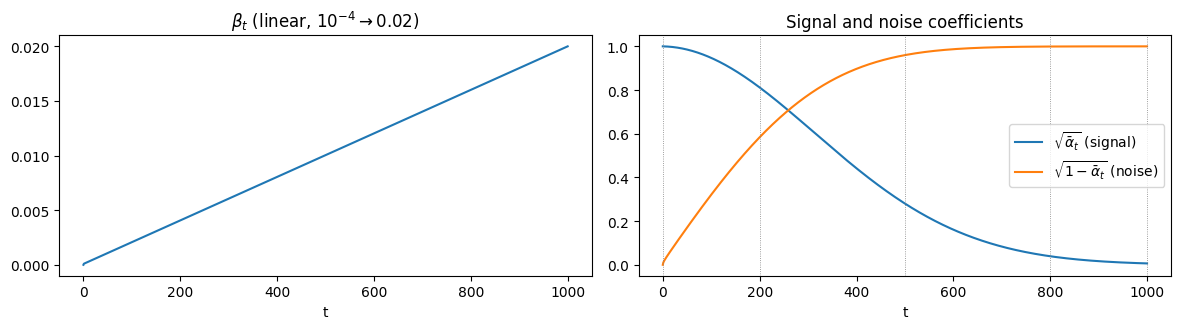

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ts = np.arange(T + 1)
ax[0].plot(ts, betas.cpu()); ax[0].set_title(r"$\beta_t$ (linear, $10^{-4} \to 0.02$)"); ax[0].set_xlabel("t")
ax[1].plot(ts, alpha_bars.sqrt().cpu(), label=r"$\sqrt{\bar\alpha_t}$ (signal)")
ax[1].plot(ts, (1 - alpha_bars).sqrt().cpu(), label=r"$\sqrt{1-\bar\alpha_t}$ (noise)")
for t in show_ts: ax[1].axvline(t, color="gray", lw=0.6, ls=":")
ax[1].set_xlabel("t"); ax[1].legend(); ax[1].set_title("Signal and noise coefficients")
plt.tight_layout(); plt.savefig(FIG_DIR / "2_schedule.png", dpi=150); plt.show()

**Observation.** At $t = 200$ ($\bar\alpha_t = 0.66$) the garment is still clearly recognizable, but its edges are already broken up. By $t = 500$ the signal coefficient is still 0.28, yet the decoded image shows no trace of the object. By $t = 800$ and $t = 1000$ ($\bar\alpha_t = 0.0015$ and $4\times10^{-5}$) the decodings cannot be told apart. Two things differ from pixel-space diffusion (HW8):

* **Noise in latent space does not decode to pixel noise.** The decoder turns any latent, including an off-manifold noisy one, into smooth "swirl" textures at the VAE's 8-pixel patch scale. The image therefore loses its identity faster than $\sqrt{\bar\alpha_t}$ alone would suggest: the decoder amplifies the noise component into strong structure.
* **The schedule reaches pure noise.** $\bar\alpha_{1000} = 4\times10^{-5}$, so $z_T$ really is $\mathcal N(0, I)$ (see the histograms, which go from a multi-peaked latent distribution at $t=0$ to a Gaussian). Sampling from $\mathcal N(0, I)$ therefore matches training. This avoids the mismatch we found in HW8 with $T = 100$.

## 3. Conditional denoising U-Net with self- and cross-attention

$\epsilon_\theta(z_t, t, y)$ predicts the noise in a 4×16×16 latent.

| Component | Implementation |
|---|---|
| Input / output | 4×16×16 latent → 4×16×16 noise prediction (the output conv is zero-initialized) |
| Channels | base 64, multipliers (1, 2, 4) → 64 @ 16×16, 128 @ 8×8, 256 @ 4×4 |
| Time | sinusoidal embedding (dim 64) → Linear–SiLU–Linear → 256-d |
| Label | `nn.Embedding(11, 256)` (10 classes + null label 10), **added** to the time embedding |
| ResBlock | GroupNorm(32)–SiLU–Conv3×3, + projected (time + label) embedding, GroupNorm–SiLU–Dropout(0.1)–Conv3×3, residual (1×1 conv when channels change) |
| Attention | after every ResBlock at **16×16**, and in the **bottleneck** (4×4): multi-head **self-attention** over the H·W latent tokens, then **cross-attention** from those tokens to 4 learned label tokens (`nn.Embedding(11, 4·128)`) |
| Down / up | stride-2 conv / nearest upsample + conv. Skip connections concatenate every encoder activation into the matching decoder ResBlock |

The class reaches the network in two ways. The additive embedding shifts every ResBlock's features, as in the original CFG paper. The cross-attention lets each spatial position look up the label information it needs, as in LDM / Stable Diffusion with text tokens. The context uses **4 tokens rather than 1**: with a single key, the softmax is always 1, so cross-attention would reduce to adding the same vector at every position.

Classifier-free guidance needs **one network that is both conditional and unconditional**. During training each label is replaced by the null label 10 with probability 0.1, so the model also learns $\epsilon_\theta(z_t, t, \varnothing)$.

In [9]:
N_CTX, CTX_DIM = 4, 128                                          # label -> 4 context tokens for cross-attention

class SinusoidalEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        half = self.dim // 2
        freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / half)
        args = t.float()[:, None] * freqs[None]
        return torch.cat([args.sin(), args.cos()], dim=1)


class ResBlock(nn.Module):
    # GroupNorm -> SiLU -> Conv, with the (time + label) embedding added between the two convs
    def __init__(self, cin, cout, emb_dim, dropout=0.1):
        super().__init__()
        self.norm1 = nn.GroupNorm(32, cin)
        self.conv1 = nn.Conv2d(cin, cout, 3, padding=1)
        self.emb = nn.Linear(emb_dim, cout)
        self.norm2 = nn.GroupNorm(32, cout)
        self.drop = nn.Dropout(dropout)
        self.conv2 = nn.Conv2d(cout, cout, 3, padding=1)
        self.skip = nn.Conv2d(cin, cout, 1) if cin != cout else nn.Identity()

    def forward(self, x, emb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.emb(F.silu(emb))[:, :, None, None]
        h = self.conv2(self.drop(F.silu(self.norm2(h))))
        return h + self.skip(x)


class AttnBlock(nn.Module):
    # Self-attention over the H*W latent tokens, then cross-attention from those tokens to the label context
    def __init__(self, ch, heads=4):
        super().__init__()
        self.norm1 = nn.GroupNorm(32, ch)
        self.self_attn = nn.MultiheadAttention(ch, heads, batch_first=True)
        self.norm2 = nn.LayerNorm(ch)
        self.cross_attn = nn.MultiheadAttention(ch, heads, kdim=CTX_DIM, vdim=CTX_DIM, batch_first=True)

    def forward(self, x, ctx):
        B, C, H, W = x.shape
        h = self.norm1(x).flatten(2).transpose(1, 2)                      # (B, HW, C)
        tok = x.flatten(2).transpose(1, 2) + self.self_attn(h, h, h, need_weights=False)[0]
        h = self.norm2(tok)
        tok = tok + self.cross_attn(h, ctx, ctx, need_weights=False)[0]
        return tok.transpose(1, 2).reshape(B, C, H, W)


class LatentUNet(nn.Module):
    def __init__(self, in_ch=4, base=BASE_CH, mults=CH_MULT, n_res=N_RES, attn_res=(16,), size=16, emb_dim=256):
        super().__init__()
        self.time_emb = nn.Sequential(SinusoidalEmbedding(base), nn.Linear(base, emb_dim), nn.SiLU(), nn.Linear(emb_dim, emb_dim))
        self.label_emb = nn.Embedding(N_CLASSES + 1, emb_dim)           # index 10 = null label
        self.ctx_emb = nn.Embedding(N_CLASSES + 1, N_CTX * CTX_DIM)     # label -> N_CTX cross-attention tokens
        self.conv_in = nn.Conv2d(in_ch, base, 3, padding=1)

        self.down = nn.ModuleList()
        chans, ch, res = [base], base, size
        for i, m in enumerate(mults):
            for _ in range(n_res):
                self.down.append(nn.ModuleList([ResBlock(ch, base * m, emb_dim),
                                                AttnBlock(base * m) if res in attn_res else nn.Identity()]))
                ch = base * m
                chans.append(ch)
            if i < len(mults) - 1:
                self.down.append(nn.Conv2d(ch, ch, 3, stride=2, padding=1))
                chans.append(ch)
                res //= 2

        self.mid1, self.mid_attn, self.mid2 = ResBlock(ch, ch, emb_dim), AttnBlock(ch), ResBlock(ch, ch, emb_dim)

        self.up = nn.ModuleList()
        for i, m in reversed(list(enumerate(mults))):
            for _ in range(n_res + 1):
                self.up.append(nn.ModuleList([ResBlock(ch + chans.pop(), base * m, emb_dim),
                                              AttnBlock(base * m) if res in attn_res else nn.Identity()]))
                ch = base * m
            if i > 0:
                self.up.append(nn.Sequential(nn.Upsample(scale_factor=2, mode="nearest"), nn.Conv2d(ch, ch, 3, padding=1)))
                res *= 2

        self.out = nn.Sequential(nn.GroupNorm(32, ch), nn.SiLU(), nn.Conv2d(ch, in_ch, 3, padding=1))
        nn.init.zeros_(self.out[-1].weight); nn.init.zeros_(self.out[-1].bias)

    def forward(self, x, t, y):
        emb = self.time_emb(t) + self.label_emb(y)                         # combine time + label embeddings
        ctx = self.ctx_emb(y).view(-1, N_CTX, CTX_DIM)
        h = self.conv_in(x)
        hs = [h]
        for layer in self.down:
            if isinstance(layer, nn.ModuleList):
                h = layer[0](h, emb)
                h = layer[1](h, ctx) if isinstance(layer[1], AttnBlock) else h
            else:
                h = layer(h)
            hs.append(h)
        h = self.mid2(self.mid_attn(self.mid1(h, emb), ctx), emb)
        for layer in self.up:
            if isinstance(layer, nn.ModuleList):
                h = layer[0](torch.cat([h, hs.pop()], dim=1), emb)
                h = layer[1](h, ctx) if isinstance(layer[1], AttnBlock) else h
            else:
                h = layer(h)
        return self.out(h)


torch.manual_seed(SEED)
model = LatentUNet().to(device)
n_attn = sum(isinstance(m, AttnBlock) for m in model.modules())
print(f"LatentUNet: {sum(p.numel() for p in model.parameters()):,} parameters, "
      f"{sum(isinstance(m, ResBlock) for m in model.modules())} ResBlocks, {n_attn} attention blocks "
      f"({n_attn - 1} at 16x16 + 1 bottleneck)")
with torch.no_grad():
    out = model(Z_train[:2], torch.tensor([1, T], device=device), torch.tensor([3, NULL_LABEL], device=device))
print("output shape:", tuple(out.shape))

LatentUNet: 14,822,916 parameters, 17 ResBlocks, 6 attention blocks (5 at 16x16 + 1 bottleneck)


output shape: (2, 4, 16, 16)


## 4. Training

For each latent: draw $t \sim \mathcal U\{1,\dots,T\}$ and $\epsilon \sim \mathcal N(0, I)$, build $z_t$ with `q_sample`, replace the label with the null label with probability 0.1, and minimize

$$L = \big\lVert \epsilon - \epsilon_\theta(z_t, t, y) \big\rVert^2 .$$

The run uses AdamW at the assignment's constant learning rate $2\times10^{-5}$ for 50 epochs (batch 128, gradient-norm clipping at 1). We also keep an **EMA** of the weights (decay warmed up to 0.999, the same as HW8) and sample from it. A checkpoint is written after every epoch, so an interrupted run can resume. A resumed run reproduces the weights but not the exact random stream.

In [10]:
def train(model, epochs=EPOCHS):
    opt = torch.optim.AdamW(model.parameters(), lr=LR)
    ema = copy.deepcopy(model).eval().requires_grad_(False)
    start, step, iter_losses, epoch_losses, train_time = 0, 0, [], [], 0.0
    if CKPT.exists():                                             # resume (or reload a finished run)
        ck = torch.load(CKPT, map_location=device)
        model.load_state_dict(ck["model"]); ema.load_state_dict(ck["ema"]); opt.load_state_dict(ck["opt"])
        start, step, iter_losses, epoch_losses, train_time = ck["epoch"], ck["step"], ck["iter_losses"], ck["epoch_losses"], ck["train_time"]
        print(f"loaded checkpoint at epoch {start}/{epochs}")

    steps_per_epoch = math.ceil(N_TRAIN / BATCH_SIZE)
    for epoch in range(start, epochs):
        model.train()
        t0 = time.time()
        perm = torch.randperm(N_TRAIN, device=device)
        running = 0.0
        for i in range(steps_per_epoch):
            idx = perm[i * BATCH_SIZE:(i + 1) * BATCH_SIZE]
            z0, y = Z_train[idx], y_train_d[idx]
            y = torch.where(torch.rand(len(y), device=device) < P_UNCOND, torch.full_like(y, NULL_LABEL), y)   # label dropout
            t = torch.randint(1, T + 1, (len(z0),), device=device)
            zt, eps = q_sample(z0, t)
            loss = F.mse_loss(model(zt, t, y), eps)                 # L = MSE(eps, eps_theta(z_t, t, y))

            opt.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            step += 1
            decay = min(0.999, (1 + step) / (10 + step))          # EMA warm-up
            with torch.no_grad():
                for pe, pm in zip(ema.parameters(), model.parameters()):
                    pe.lerp_(pm, 1 - decay)

            l = loss.item()
            iter_losses.append(l); running += l
        epoch_losses.append(running / steps_per_epoch)
        train_time += time.time() - t0
        print(f"epoch {epoch + 1:3d}/{epochs}  loss {epoch_losses[-1]:.4f}  ({time.time() - t0:.0f}s, total {train_time / 60:.1f} min)", flush=True)
        torch.save({"model": model.state_dict(), "ema": ema.state_dict(), "opt": opt.state_dict(), "epoch": epoch + 1,
                    "step": step, "iter_losses": iter_losses, "epoch_losses": epoch_losses, "train_time": train_time}, CKPT)
    return ema, iter_losses, epoch_losses, train_time


ema, iter_losses, epoch_losses, train_time = train(model)
print(f"training time {train_time / 60:.1f} min, {len(iter_losses)} steps, final epoch loss {epoch_losses[-1]:.4f}")

epoch   1/50  loss 0.6873  (909s, total 15.2 min)


epoch   2/50  loss 0.2730  (669s, total 26.3 min)


epoch   3/50  loss 0.1628  (537s, total 35.3 min)


epoch   4/50  loss 0.1382  (692s, total 46.8 min)


epoch   5/50  loss 0.1306  (638s, total 57.4 min)


...

epoch  47/50  loss 0.0957  (664s, total 2729.2 min)


epoch  48/50  loss 0.0964  (544s, total 2738.3 min)


epoch  49/50  loss 0.0961  (510s, total 2746.8 min)


epoch  50/50  loss 0.0955  (503s, total 2755.1 min)


training time 2755.1 min, 23450 steps, final epoch loss 0.0955


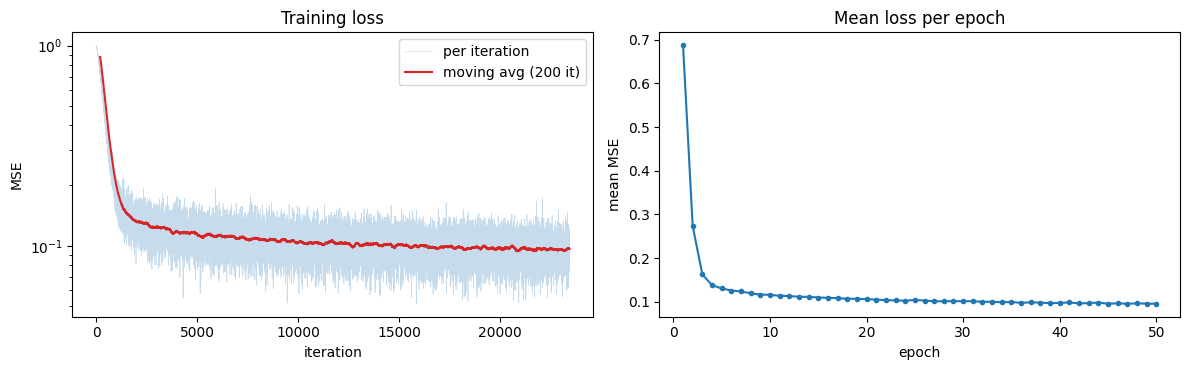

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
it = np.arange(len(iter_losses))
k = min(200, len(iter_losses))
smooth = np.convolve(iter_losses, np.ones(k) / k, mode="valid")
ax[0].plot(it, iter_losses, alpha=0.25, lw=0.5, label="per iteration")
ax[0].plot(it[k - 1:], smooth, color="tab:red", label=f"moving avg ({k} it)")
ax[0].set_yscale("log"); ax[0].set_xlabel("iteration"); ax[0].set_ylabel("MSE"); ax[0].legend(); ax[0].set_title("Training loss")
ax[1].plot(np.arange(1, len(epoch_losses) + 1), epoch_losses, marker="o", ms=3)
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("mean MSE"); ax[1].set_title("Mean loss per epoch")
plt.tight_layout(); plt.savefig(FIG_DIR / "4_training_loss.png", dpi=150); plt.show()

    t   cond MSE  uncond MSE
    1     0.9506      0.9541
   10     0.7658      0.7697
   50     0.4640      0.4665
  100     0.2960      0.2978
  200     0.1451      0.1464
  300     0.0755      0.0765
  400     0.0383      0.0391
  500     0.0182      0.0191
  600     0.0081      0.0093
  700     0.0034      0.0043
  800     0.0016      0.0019
  900     0.0011      0.0011
 1000     0.0011      0.0010


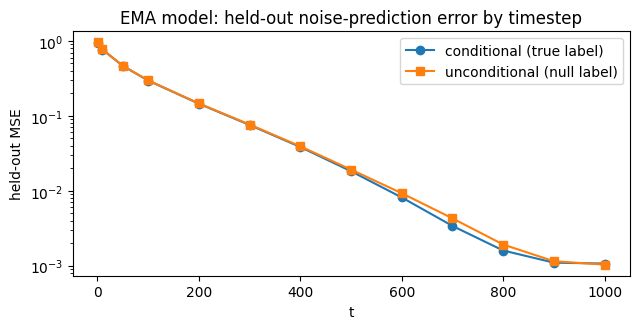

In [12]:
@torch.no_grad()
def loss_per_t(net, n=1000, t_vals=(1, 10, 50, 100, 200, 300, 400, 500, 600, 700, 800, 900, 1000)):
    # Held-out noise-prediction MSE, conditional (true label) and unconditional (null label)
    z0 = z_test[:n]
    y = y_test[:len(z0)].to(device)
    g = torch.Generator(device="cpu").manual_seed(SEED + 6)
    out = []
    for t_val in t_vals:
        t = torch.full((len(z0),), t_val, device=device, dtype=torch.long)
        zt, eps = q_sample(z0, t, torch.randn(z0.shape, generator=g).to(device))
        out.append((t_val, F.mse_loss(net(zt, t, y), eps).item(), F.mse_loss(net(zt, t, torch.full_like(y, NULL_LABEL)), eps).item()))
    return out

lpt = loss_per_t(ema)
print(f"{'t':>5}{'cond MSE':>11}{'uncond MSE':>12}")
for t_val, c, u in lpt: print(f"{t_val:>5}{c:>11.4f}{u:>12.4f}")
plt.figure(figsize=(6.5, 3.4))
plt.plot([r[0] for r in lpt], [r[1] for r in lpt], marker="o", label="conditional (true label)")
plt.plot([r[0] for r in lpt], [r[2] for r in lpt], marker="s", label="unconditional (null label)")
plt.yscale("log"); plt.xlabel("t"); plt.ylabel("held-out MSE"); plt.legend(); plt.title("EMA model: held-out noise-prediction error by timestep")
plt.tight_layout(); plt.savefig(FIG_DIR / "4_loss_per_t.png", dpi=150); plt.show()

## 5. Sampling with classifier-free guidance

At each reverse step the network runs twice, once with the class label and once with the null label (batched together), and the two predictions are combined:

$$\epsilon = (1+w)\,\epsilon_\theta(z_t, t, y) - w\,\epsilon_\theta(z_t, t, \varnothing),\qquad w = 3.$$

The guided $\epsilon$ is used in the DDPM ancestral update (Ho et al., Algorithm 2, $\sigma_t^2 = \beta_t$), starting from $z_T \sim \mathcal N(0, I)$ and running all 1000 steps:

$$z_{t-1} = \frac{1}{\sqrt{\alpha_t}}\Big(z_t - \frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\,\epsilon\Big) + \sqrt{\beta_t}\,\xi,\qquad \xi\sim\mathcal N(0,I).$$

The final $z_0$ is divided by $s$ and decoded by the VAE. In the 64-image grid, image $i$ has label $i \bmod 10$.

DDPM 1000 steps x 2 passes (CFG w=3.0) for 64 latents: 377.1s sampling + 14.4s VAE decoding
generated latents: mean -0.003  std 1.274   (training latents: std 1.265)


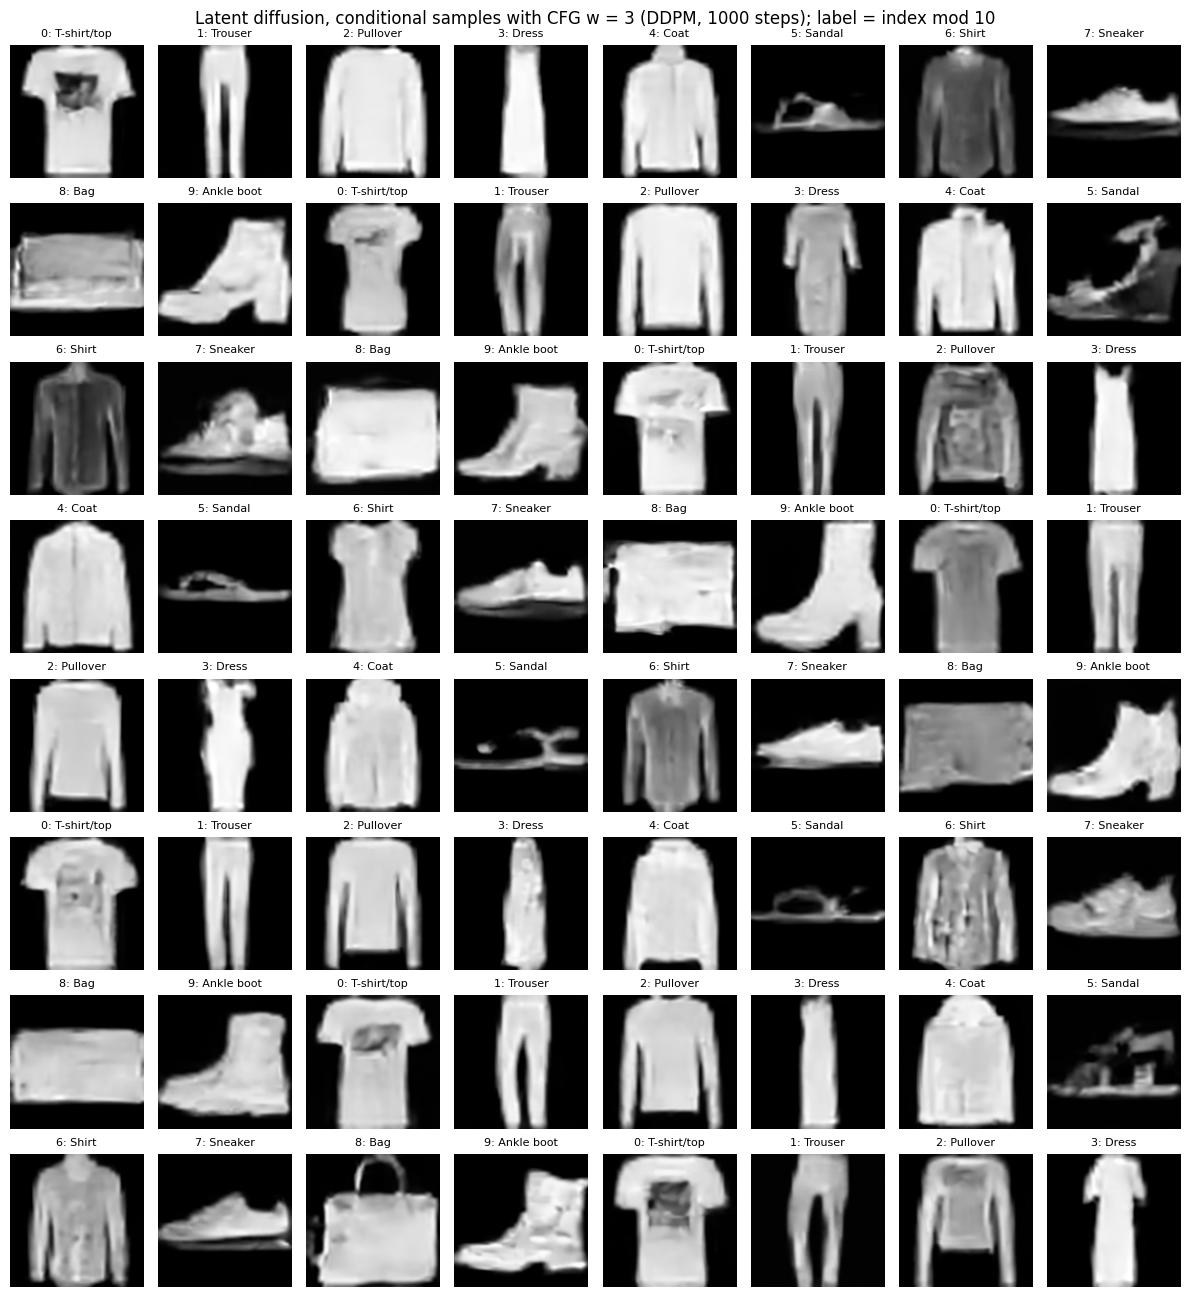

In [13]:
def guided_eps(net, z, t, y, w):
    # Classifier-free guidance: eps = (1 + w) eps_cond - w eps_uncond (w = 0 -> plain conditional model)
    if w == 0:
        return net(z, t, y)
    eps_c, eps_u = net(torch.cat([z, z]), torch.cat([t, t]), torch.cat([y, torch.full_like(y, NULL_LABEL)])).chunk(2)
    return (1 + w) * eps_c - w * eps_u

@torch.no_grad()
def ddpm_sample(net, z_T, y, w=GUIDANCE, gen=None, keep=()):
    z, traj = z_T.clone(), {}
    if T in keep: traj[T] = z.clone()
    for t in range(T, 0, -1):
        tt = torch.full((len(z),), t, device=device, dtype=torch.long)
        eps = guided_eps(net, z, tt, y, w)
        mean = (z - betas[t] / (1 - alpha_bars[t]).sqrt() * eps) / alphas[t].sqrt()
        z = mean + betas[t].sqrt() * torch.randn(z.shape, generator=gen).to(device) if t > 1 else mean
        if t - 1 in keep: traj[t - 1] = z.clone()
    return z, traj


N_SHOW = 64
labels_show = torch.arange(N_SHOW, device=device) % N_CLASSES              # class labels 0-9 repeated
z_T = torch.randn(N_SHOW, 4, 16, 16, generator=torch.Generator(device="cpu").manual_seed(SEED + 2)).to(device)
keep_ts = [1000, 800, 600, 400, 200, 100, 0]

sync(); t0 = time.time()
z_gen, traj = ddpm_sample(ema, z_T, labels_show, w=GUIDANCE, gen=torch.Generator(device="cpu").manual_seed(SEED + 4), keep=keep_ts)
sync(); t_sample = time.time() - t0
x_gen = decode(z_gen)
sync(); t_total = time.time() - t0
print(f"DDPM 1000 steps x 2 passes (CFG w={GUIDANCE}) for {N_SHOW} latents: {t_sample:.1f}s sampling + {t_total - t_sample:.1f}s VAE decoding")
print(f"generated latents: mean {z_gen.mean().item():.3f}  std {z_gen.std().item():.3f}   (training latents: std {Z_train.std().item():.3f})")

fig, axes = plt.subplots(8, 8, figsize=(12, 13.2))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_gen[i, 0].cpu(), cmap="gray", vmin=0, vmax=1); ax.axis("off")
    ax.set_title(f"{labels_show[i].item()}: {CLASSES[labels_show[i]]}", fontsize=8)
fig.suptitle(f"Latent diffusion, conditional samples with CFG w = {GUIDANCE:g} (DDPM, 1000 steps); label = index mod 10", fontsize=12)
plt.tight_layout(); plt.savefig(FIG_DIR / "5_cfg_samples_grid64.png", dpi=150, bbox_inches="tight"); plt.show()

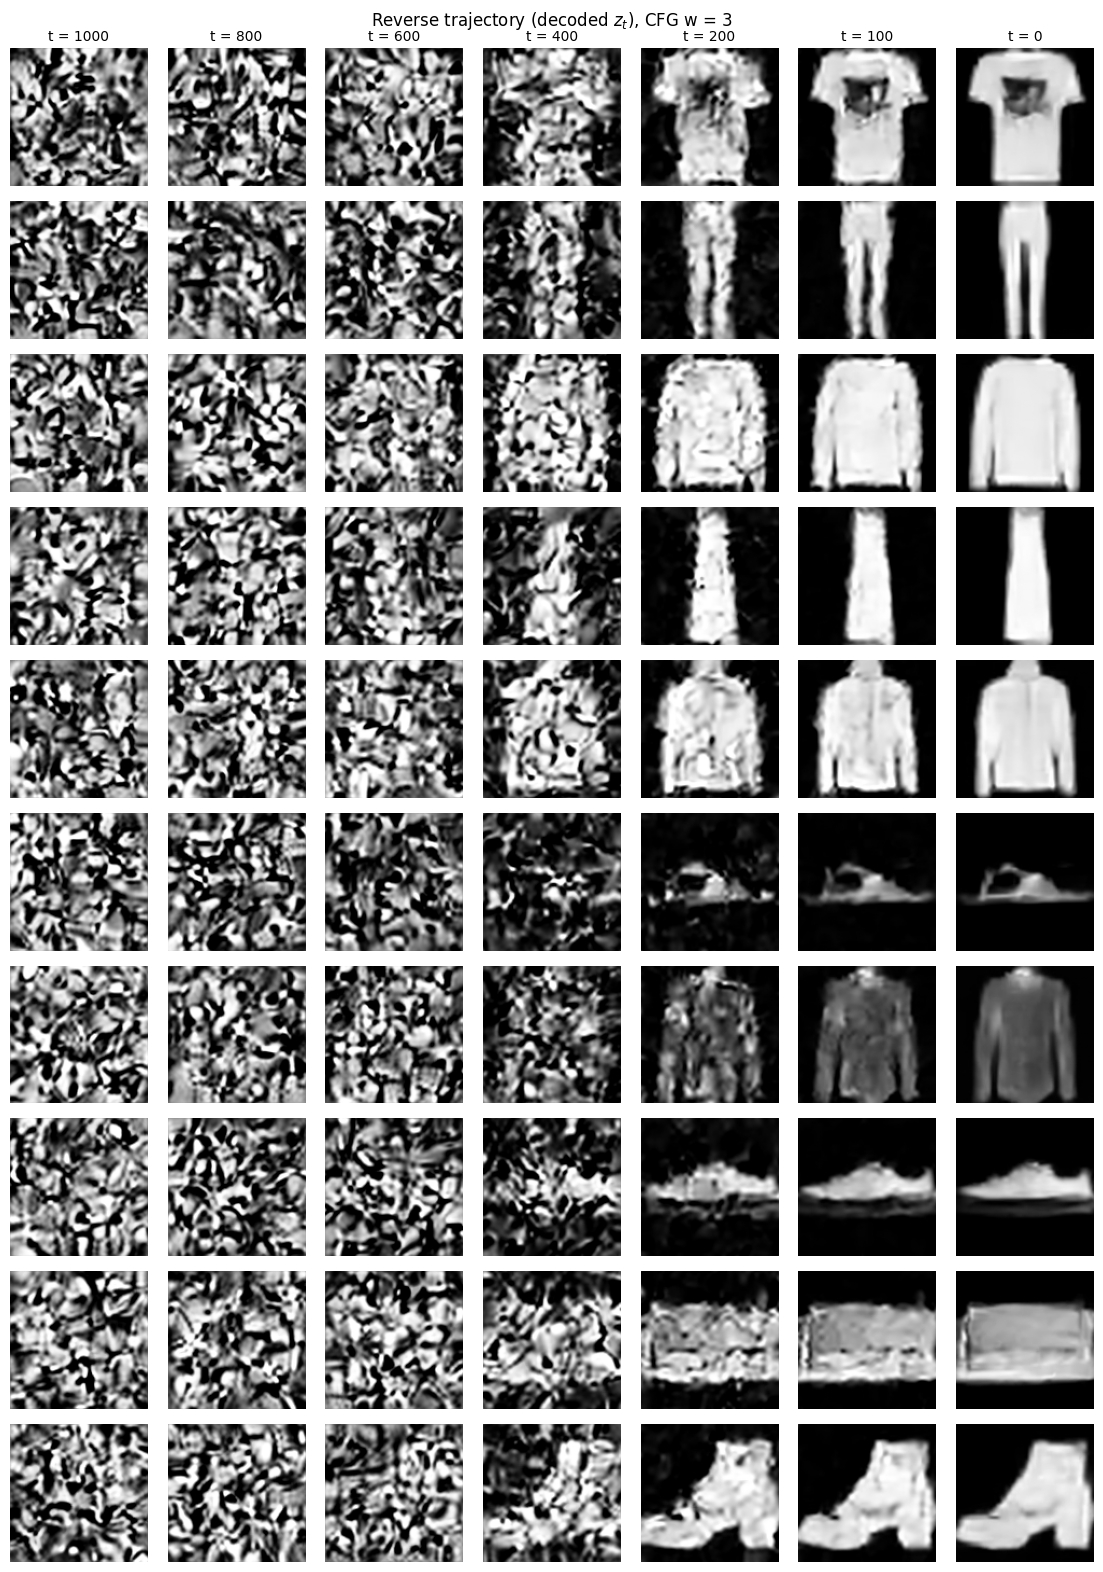

In [14]:
rows_traj = list(range(10))                                     # one sample per class
dec = decode(torch.cat([traj[t][rows_traj] for t in keep_ts])).view(len(keep_ts), len(rows_traj), 1, IMG_SIZE, IMG_SIZE)
fig, axes = plt.subplots(len(rows_traj), len(keep_ts), figsize=(1.6 * len(keep_ts), 1.6 * len(rows_traj)))
for j, t in enumerate(keep_ts):
    axes[0, j].set_title(f"t = {t}", fontsize=10)
    for i in range(len(rows_traj)):
        axes[i, j].imshow(dec[j, i, 0].cpu(), cmap="gray", vmin=0, vmax=1); axes[i, j].axis("off")
fig.suptitle("Reverse trajectory (decoded $z_t$), CFG w = 3")
plt.tight_layout(); plt.savefig(FIG_DIR / "5_reverse_trajectory.png", dpi=150); plt.show()

### Evaluating the samples

FID needs an ImageNet Inception network and many thousands of samples, so instead we use a **judge classifier**, as in HW8: a small CNN trained on real FashionMNIST at 28×28. Generated images are decoded and area-downsampled to 28×28 before being judged. We report:

* **class accuracy**: how often the judge's prediction equals the label the sample was conditioned on. This measures whether conditioning works;
* **mean confidence**: the mean max-softmax, a proxy for how "typical" a sample looks;
* **intra-class diversity**: the mean pairwise L2 distance between 28×28 samples of the same class, compared with the same statistic for real test images.

Two reference points give upper bounds: real test images, and the VAE reconstructions from Part 1, which pass through the same 128 px → VAE → 28 px pipeline as the samples.

In [15]:
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.Conv2d(32, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Dropout(0.3), nn.Linear(128, 10))

    def forward(self, x):                                        # x in [0,1]
        return self.net(x * 2 - 1)

torch.manual_seed(SEED)
clf = Classifier().to(device)
clf_opt = torch.optim.Adam(clf.parameters(), lr=1e-3)
Xtr_d, ytr_d = X_train.to(device), y_train.to(device)
for ep in range(5):
    clf.train()
    perm = torch.randperm(len(Xtr_d), device=device)
    for i in range(0, len(Xtr_d), 256):
        b = perm[i:i + 256]
        loss = F.cross_entropy(clf(Xtr_d[b]), ytr_d[b])
        clf_opt.zero_grad(); loss.backward(); clf_opt.step()
clf.eval()
del Xtr_d

@torch.no_grad()
def judge(x28, y):
    # x28: (B,1,28,28) in [0,1]; y: intended labels
    p = F.softmax(clf(x28.to(device)), dim=1)
    pred = p.argmax(1).cpu()
    return {"acc": (pred == y.cpu()).float().mean().item(), "conf": p.max(1).values.mean().item(), "pred": pred}

def diversity(x28, y):
    # Mean pairwise L2 distance between images of the same class, averaged over classes
    d = []
    for c in range(N_CLASSES):
        xc = x28[y.cpu() == c].flatten(1).cpu()
        if len(xc) > 1:
            D = torch.cdist(xc, xc)
            d.append(D.sum().item() / (len(xc) * (len(xc) - 1)))
    return float(np.mean(d))

ref_real = judge(X_test, y_test)
ref_rec = judge(to28(x_rec).cpu(), y_test[:N_RECON])
div_real = diversity(X_test[:N_EVAL], y_test[:N_EVAL])
grid = judge(to28(x_gen).cpu(), labels_show)
print(f"judge accuracy on real test images        : {ref_real['acc']:.4f}  (conf {ref_real['conf']:.3f})")
print(f"judge accuracy on VAE reconstructions      : {ref_rec['acc']:.4f}  (conf {ref_rec['conf']:.3f}, {N_RECON} test images)")
print(f"64-image CFG grid (w={GUIDANCE:g}, DDPM 1000)    : {grid['acc']:.4f}  (conf {grid['conf']:.3f}, {int(grid['acc'] * N_SHOW)}/{N_SHOW} correct)")
print("grid misclassifications (index: intended -> judged):",
      [(i, CLASSES[labels_show[i]], CLASSES[grid['pred'][i]]) for i in range(N_SHOW) if grid['pred'][i] != labels_show[i].item()])

judge accuracy on real test images        : 0.9129  (conf 0.927)
judge accuracy on VAE reconstructions      : 0.9160  (conf 0.912, 2000 test images)
64-image CFG grid (w=3, DDPM 1000)    : 1.0000  (conf 0.985, 64/64 correct)
grid misclassifications (index: intended -> judged): []


### Effect of the guidance scale

To isolate $w$, we generate `N_EVAL` = 500 samples (50 per class) for $w \in \{0, 1, 3, 5\}$ from the **same** starting noise, plus 500 samples from the purely unconditional model (null label, no guidance). One extra network pass per step makes 1000-step DDPM sampling of 500 images cost about an hour per setting on this machine. This sweep therefore uses deterministic **DDIM** (η = 0) with 50 steps (Song et al., the HW8 sampler), which runs on the same trained network. The required $w = 3$ grid above uses full DDPM.

In [16]:
@torch.no_grad()
def ddim_sample(net, z_T, y, w, n_steps=50):
    taus = torch.linspace(T, 0, n_steps + 1).round().long().tolist()
    z = z_T.clone()
    for t, s in zip(taus[:-1], taus[1:]):
        tt = torch.full((len(z),), t, device=device, dtype=torch.long)
        eps = guided_eps(net, z, tt, y, w)
        z0_hat = (z - (1 - alpha_bars[t]).sqrt() * eps) / alpha_bars[t].sqrt()
        z = alpha_bars[s].sqrt() * z0_hat + (1 - alpha_bars[s]).sqrt() * eps
    return z

labels_eval = torch.arange(N_EVAL, device=device) % N_CLASSES
z_T_eval = torch.randn(N_EVAL, 4, 16, 16, generator=torch.Generator(device="cpu").manual_seed(SEED + 3)).to(device)

sweep, sweep_imgs = [], {}
for w in [0.0, 1.0, 3.0, 5.0]:
    sync(); t0 = time.time()
    x28 = to28(decode(torch.cat([ddim_sample(ema, z_T_eval[i:i + 250], labels_eval[i:i + 250], w) for i in range(0, N_EVAL, 250)]))).cpu()
    sync(); dt = time.time() - t0
    r = judge(x28, labels_eval)
    sweep.append((w, r["acc"], r["conf"], diversity(x28, labels_eval), dt))
    sweep_imgs[w] = x28
    print(f"w = {w:3.1f}  acc {r['acc']:.4f}  conf {r['conf']:.3f}  diversity {sweep[-1][3]:.3f}  ({dt:.0f}s)", flush=True)

null = torch.full_like(labels_eval, NULL_LABEL)
x28_unc = to28(decode(torch.cat([ddim_sample(ema, z_T_eval[i:i + 250], null[i:i + 250], 0.0) for i in range(0, N_EVAL, 250)]))).cpu()
r_unc = judge(x28_unc, labels_eval)
counts_unc = torch.bincount(r_unc["pred"], minlength=N_CLASSES)
q = counts_unc.float() / counts_unc.sum()
H_unc = -(q[q > 0] * q[q > 0].log2()).sum().item()
print(f"\nunconditional (null label): judge conf {r_unc['conf']:.3f}, predicted-class entropy {H_unc:.3f} bits (max {math.log2(N_CLASSES):.3f})")
print("unconditional predicted-class counts:", dict(zip(CLASSES, counts_unc.tolist())))
print(f"\nreal test images: diversity {div_real:.3f}, judge acc {ref_real['acc']:.4f}, conf {ref_real['conf']:.3f}")

w = 0.0  acc 0.8240  conf 0.863  diversity 7.964  (189s)


w = 1.0  acc 0.9600  conf 0.944  diversity 7.038  (297s)


w = 3.0  acc 0.9880  conf 0.975  diversity 6.487  (298s)


w = 5.0  acc 0.9960  conf 0.981  diversity 6.358  (407s)



unconditional (null label): judge conf 0.843, predicted-class entropy 3.284 bits (max 3.322)
unconditional predicted-class counts: {'T-shirt/top': 45, 'Trouser': 47, 'Pullover': 50, 'Dress': 50, 'Coat': 79, 'Sandal': 52, 'Shirt': 33, 'Sneaker': 49, 'Bag': 58, 'Ankle boot': 37}

real test images: diversity 8.659, judge acc 0.9129, conf 0.927


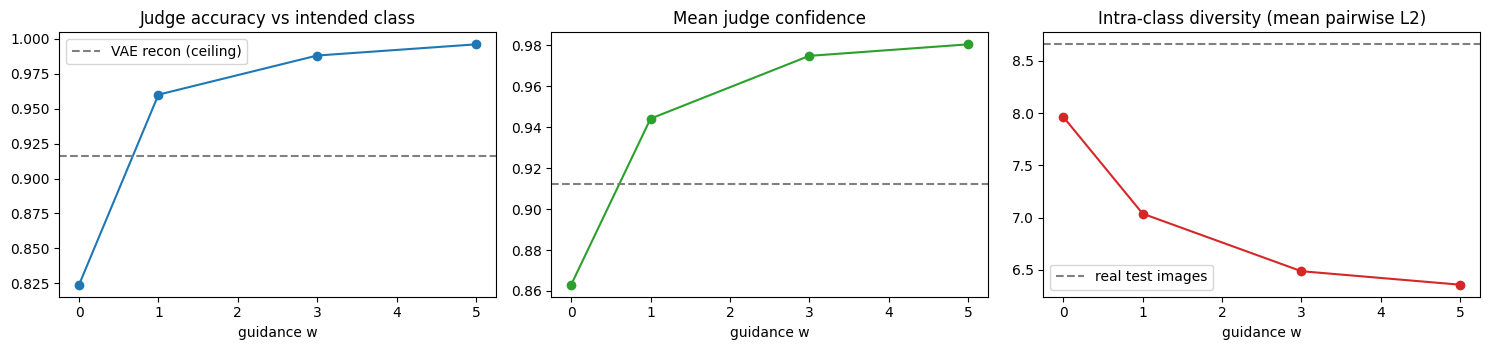

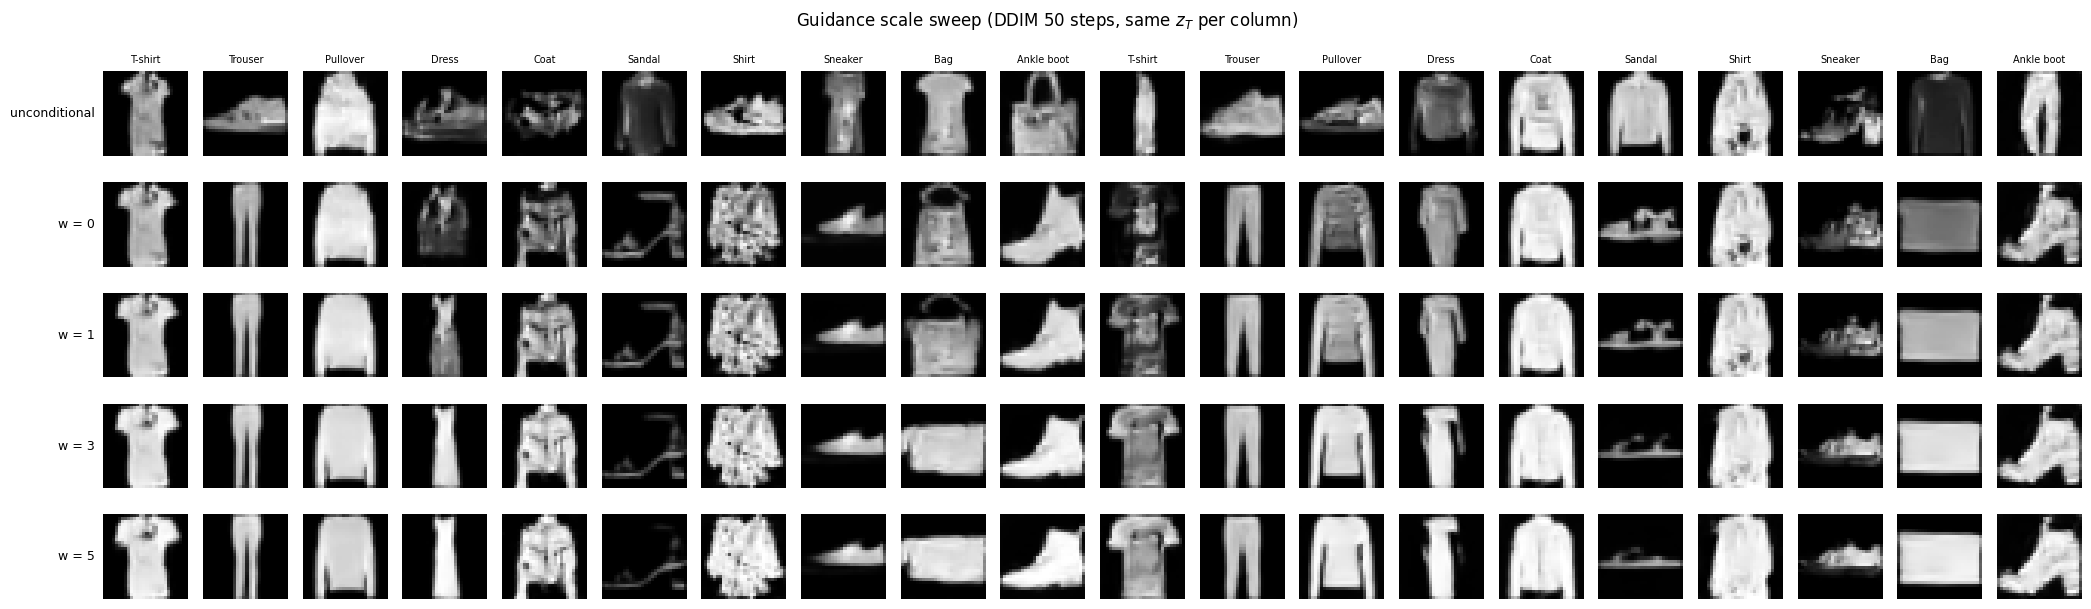

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ws = [r[0] for r in sweep]
ax[0].plot(ws, [r[1] for r in sweep], marker="o"); ax[0].axhline(ref_rec["acc"], ls="--", color="gray", label="VAE recon (ceiling)")
ax[0].set_title("Judge accuracy vs intended class"); ax[0].set_xlabel("guidance w"); ax[0].legend()
ax[1].plot(ws, [r[2] for r in sweep], marker="o", color="tab:green"); ax[1].axhline(ref_rec["conf"], ls="--", color="gray")
ax[1].set_title("Mean judge confidence"); ax[1].set_xlabel("guidance w")
ax[2].plot(ws, [r[3] for r in sweep], marker="o", color="tab:red"); ax[2].axhline(div_real, ls="--", color="gray", label="real test images")
ax[2].set_title("Intra-class diversity (mean pairwise L2)"); ax[2].set_xlabel("guidance w"); ax[2].legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "5_guidance_sweep_metrics.png", dpi=150); plt.show()

# Same starting noise in each column; rows differ only in w
cols = [int((labels_eval == c).nonzero()[k]) for k in range(2) for c in range(N_CLASSES)]
fig, axes = plt.subplots(5, len(cols), figsize=(1.05 * len(cols), 6.3))
row_imgs = [("unconditional", x28_unc)] + [(f"w = {w:g}", sweep_imgs[w]) for w in ws]
for r, (name, xs) in enumerate(row_imgs):
    for j, i in enumerate(cols):
        axes[r, j].imshow(xs[i, 0], cmap="gray", vmin=0, vmax=1); axes[r, j].axis("off")
        if r == 0: axes[r, j].set_title(CLASSES[labels_eval[i]].split("/")[0], fontsize=7)
    axes[r, 0].text(-0.1, 0.5, name, transform=axes[r, 0].transAxes, ha="right", va="center", fontsize=9)
fig.suptitle("Guidance scale sweep (DDIM 50 steps, same $z_T$ per column)")
plt.tight_layout(); plt.savefig(FIG_DIR / "5_guidance_sweep_samples.png", dpi=150, bbox_inches="tight"); plt.show()

## Discussion

### Summary of results

| Quantity | Value |
|---|---|
| VAE reconstruction MSE, 128×128 vs VAE input ([0,1] scale, 2,000 test images) | **0.000196** (PSNR 37.1 dB) |
| VAE reconstruction MSE, 28×28 vs original | 0.00346 (PSNR 24.6 dB), of which the resize round trip alone is 0.00317 |
| Scaled latents ($s = 0.18215$) | 4×16×16; mean −0.039, std **1.265**; per-channel means −0.12 / −1.27 / 0.66 / 0.58 |
| U-Net | 14.8M parameters, 17 ResBlocks, 6 attention blocks (5 at 16×16 + bottleneck) |
| Training loss (epoch 1 → 50) | 0.687 → **0.0955** (23,450 steps, lr 2e-5) |
| 64-image grid, CFG $w=3$, DDPM 1000 steps | **64 / 64** judged as the intended class, mean confidence 0.985 |
| Judge on real test images / on VAE reconstructions | 91.3% / 91.6% accuracy (confidence 0.927 / 0.912) |

Guidance sweep (DDIM 50 steps, 500 samples per setting, same $z_T$):

| Setting | Judge accuracy vs intended class | Mean confidence | Intra-class diversity (mean pairwise L2) |
|---|---|---|---|
| unconditional (null label) | – (class entropy 3.284 of 3.322 bits) | 0.843 | – |
| $w = 0$ (conditional only) | 82.4% | 0.863 | 7.96 |
| $w = 1$ | 96.0% | 0.944 | 7.04 |
| $w = 3$ | 98.8% | 0.975 | 6.49 |
| $w = 5$ | **99.6%** | **0.981** | 6.36 |
| real test images | 91.3% | 0.927 | **8.66** |

### 1. The VAE latent space

The pretrained SD VAE is close to lossless for FashionMNIST. At the resolution it actually operates on (128×128), the reconstruction MSE is 0.0002, and the only visible errors are faint ones along sharp edges and fine print (the "Lee" logo). Measured against the original 28×28 image, the MSE rises to 0.0035, but 0.0032 of that comes from the bilinear-up / area-down resize, which happens without the VAE. The VAE itself adds only about 0.0003. The judge classifier agrees: it scores 91.6% on reconstructions and 91.3% on the originals, so **the latent keeps all the class information**.

On "compression": the 4×16×16 latent is 48× smaller than the 3×128×128 image the VAE sees, and the U-Net only ever processes 16×16 maps. For FashionMNIST, though, the latent (1,024 numbers) is not smaller than the original 28×28 image (784 pixels). The benefit of latent diffusion here is in compute relative to diffusing at 128×128. The approach pays off for real at Stable Diffusion's 512×512 resolution, which is what this VAE was designed for.

The scaling factor $s = 0.18215$ was calibrated on natural images. On FashionMNIST it gives a latent std of 1.265 rather than 1, and channel 1 has a mean of −1.27 (mostly black backgrounds). This did not cause problems. The diffusion process reaches $\bar\alpha_T \approx 4\times10^{-5}$, so the prior is still $\mathcal N(0, I)$, and the generated latents end with std 1.274, matching the training latents (1.265). A dataset-specific $s = 1/\mathrm{std}$ would be the cleaner choice, but the assignment fixes $s$.

### 2. Training

The loss falls steeply over the first three epochs (0.687 → 0.163) and then decreases slowly, reaching 0.0955 at epoch 50. At the constant learning rate of $2\times10^{-5}$ it is still going down slightly, so more epochs or a higher or decaying learning rate would probably help a little. The held-out loss per timestep has the usual shape. At small $t$ the noise is a tiny fraction of $z_t$ and is essentially unpredictable (MSE 0.95 at $t = 1$). At large $t$, $z_t \approx \epsilon$, so predicting $\epsilon$ is trivial (MSE 0.001). Between those extremes, the conditional prediction beats the unconditional one at every $t \le 800$, with the largest relative gap around $t = 600$–$800$ (0.0034 vs 0.0043 at $t = 700$, 21% lower). That is the range where the global shape is being decided and knowing the class helps most. The label dropout worked as intended: the single network is a usable unconditional model too.

### 3. Classifier-free guidance

The required grid ($w = 3$, 1000-step DDPM, labels 0–9 repeated) is **64/64 correct** according to the judge, with mean confidence 0.985. That is *higher* than for real test images (0.927). The samples are clean and recognizable: trousers with a visible leg gap, sandals with straps, bags with handles, and T-shirts with printed graphics. They are also somewhat smoother and more "prototypical" than real images, which is the expected effect of guidance.

The sweep separates the effect of $w$, because each column starts from the same noise:

* **Fidelity rises with $w$.** Accuracy goes 82.4% → 96.0% → 98.8% → 99.6%, and confidence goes 0.863 → 0.981. Without guidance ($w = 0$), the conditional model still produces many ambiguous items, mostly confusions among the upper-body classes (T-shirt / shirt / pullover / coat). In the sample figure, for example, the first Dress column starts as a dark, bag-like object at $w = 0$ and becomes a clear dress at $w \ge 3$, from the same starting noise.
* **Diversity falls with $w$.** The mean pairwise distance within each class drops from 7.96 to 6.36, while real images sit at 8.66. Guidance pushes $\epsilon$ along $\epsilon_\text{cond} - \epsilon_\text{uncond}$, which sharpens $p(y \mid z)$ and moves samples toward the modes of each class. Shapes become simpler and textures flatter (compare rows $w = 1$ and $w = 5$).
* **The returns diminish.** Most of the gain comes from $w = 0 \to 1$. Going from $w = 3$ to $w = 5$ adds 0.8 points of accuracy and costs further diversity, so $w = 3$ is a reasonable operating point.
* **The unconditional model covers all ten classes.** Its predicted-class entropy is 3.284 bits (the maximum is 3.322), and every class gets between 33 and 79 of 500 samples. Coat is over-represented and Shirt under-represented, which partly reflects the judge's own coat/shirt confusion. No mode collapse.

The reverse trajectory shows the usual coarse-to-fine order in latent space. Through $t = 400$ the decoded latent is texture. The silhouette appears between $t = 400$ and $t = 200$, and the last 200 steps only refine edges and interior detail.

### 4. Caveats

* The judge-based metrics stand in for FID. Judge accuracy above the real-image level means "unambiguous to this classifier", not "more realistic than the data".
* The sweep uses 50-step DDIM to keep sampling time manageable. The $w = 3$ result (98.8% on 500 samples) agrees with the 1000-step DDPM grid (100% on 64).
* All results come from a single run with SEED = 1605.